# arXiv metadata: GANs and diffusion models

How much research attention did GANs get, and when did diffusion models take over? We count papers on
[arXiv](https://arxiv.org) per month, from snapshots of the [arXiv API](https://info.arxiv.org/help/api/user-manual.html)
cached in the course bucket. The API returns at most 10,000 results per query, so each query was fetched in slices by
submission date (`instructor/m04_gan/arxiv_fetch.py`):

| | API query | fetched | results |
|---|---|---|---|
| GAN | `all:GAN` | 2026-10-24 | 14,811 |
| diffusion | `(ti:diffusion OR abs:diffusion) AND (cat:cs.CV OR cat:cs.LG OR cat:cs.AI OR cat:stat.ML)` | 2026-11-15 | 29,039 |

The API's search is loose (it matches other fields and word forms), so each snapshot is then filtered in pandas:

- **GAN**: the entry contains "GAN" (case-sensitive, which excludes the semiconductor GaN) or "Generative Adversarial";
- **diffusion**: the title or abstract contains "diffusion" (any case). "Diffusion" is also a physics and mathematics
  term (heat, particles, reactions), so this query is restricted to the machine-learning categories. It still counts
  some papers that are not about diffusion *models* — graph diffusion, diffusion maps, information diffusion — which
  is the baseline before 2020.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from bs4 import BeautifulSoup

%config InlineBackend.figure_format = 'retina'
sns.set_context('paper')
sns.set_style('darkgrid')

In [2]:
!ls datasets/gan_arxiv.xml || (mkdir -p datasets && aws s3 cp s3://danylo-ucla/gan_arxiv.xml datasets/)
!ls datasets/diffusion_arxiv.xml || (mkdir -p datasets && aws s3 cp s3://danylo-ucla/diffusion_arxiv.xml datasets/)

datasets/gan_arxiv.xml


datasets/diffusion_arxiv.xml


## Loading the snapshots

Each snapshot is an Atom XML feed with one `<entry>` per paper. We keep the date of the first version (`published`),
the whole text of the entry (title, abstract, authors, comments), and the title and abstract alone.

In [3]:
def load_arxiv(path) -> pd.DataFrame:
    with open(path) as f:
        entries = BeautifulSoup(f, 'xml').find_all('entry')
    return pd.DataFrame({
        'published': pd.to_datetime([entry.published.get_text() for entry in entries]),
        'text': [entry.get_text() for entry in entries],
        'title_abstract': [entry.title.get_text() + ' ' + entry.summary.get_text() for entry in entries],
    })


gan = load_arxiv('datasets/gan_arxiv.xml')
diffusion = load_arxiv('datasets/diffusion_arxiv.xml')
print(f'GAN: {len(gan):,} entries, diffusion: {len(diffusion):,} entries')
gan.head()

GAN: 14,811 entries, diffusion: 29,039 entries


,published,text,title_abstract
0,1992-08-27 16:03:28+00:00,\nhttp://arxiv.org/abs/cond-mat/9208022v1\nEle...,Electronic and structural properties of GaN by...
1,1993-01-11 14:28:53+00:00,\nhttp://arxiv.org/abs/cond-mat/9301010v1\nUnd...,Underscreened Kondo Necklace It has been sug...
2,1993-09-28 01:51:00+00:00,\nhttp://arxiv.org/abs/cond-mat/9309044v1\nNon...,Non-Fermi Liquid Behavior In Quantum Critical ...
3,1993-09-28 02:32:00+00:00,\nhttp://arxiv.org/abs/cond-mat/9309045v1\nOn ...,"On The Multichannel Kondo Model"" A detailed ..."
4,1993-09-28 02:34:00+00:00,\nhttp://arxiv.org/abs/cond-mat/9309046v1\nKon...,Kondo Crossover In The Self-Consistent One-Loo...


The filters, and the share of each snapshot that passes:

In [4]:
gan_match = gan.text.str.contains('GAN') | gan.text.str.contains('Generative Adversarial')
diffusion_match = diffusion.title_abstract.str.contains('diffusion', case=False)
print(f'GAN: {gan_match.mean():.1%} of entries, diffusion: {diffusion_match.mean():.1%} of entries')

GAN: 61.6% of entries, diffusion: 96.9% of entries


## Papers per month

Each paper is counted in the month of its first version. The plots stop at the last full month of each snapshot.

In [5]:
def monthly_counts(published: pd.Series, last_month: str) -> pd.DataFrame:
    months = published.dt.tz_convert(None).dt.to_period('M')
    per_month = months.value_counts().sort_index()
    per_month = per_month.reindex(pd.period_range(per_month.index.min(), last_month, freq='M'), fill_value=0)
    return pd.DataFrame({'papers per month': per_month, 'cumulative papers': per_month.cumsum()})


gan_monthly = monthly_counts(gan.published[gan_match], last_month='2026-09')        # snapshot of 2026-10-24
diffusion_monthly = monthly_counts(diffusion.published[diffusion_match], last_month='2026-10')  # of 2026-11-15
gan_monthly.tail()

,papers per month,cumulative papers
2026-05,64,8907
2026-06,57,8964
2026-07,34,8998
2026-08,51,9049
2026-09,47,9096


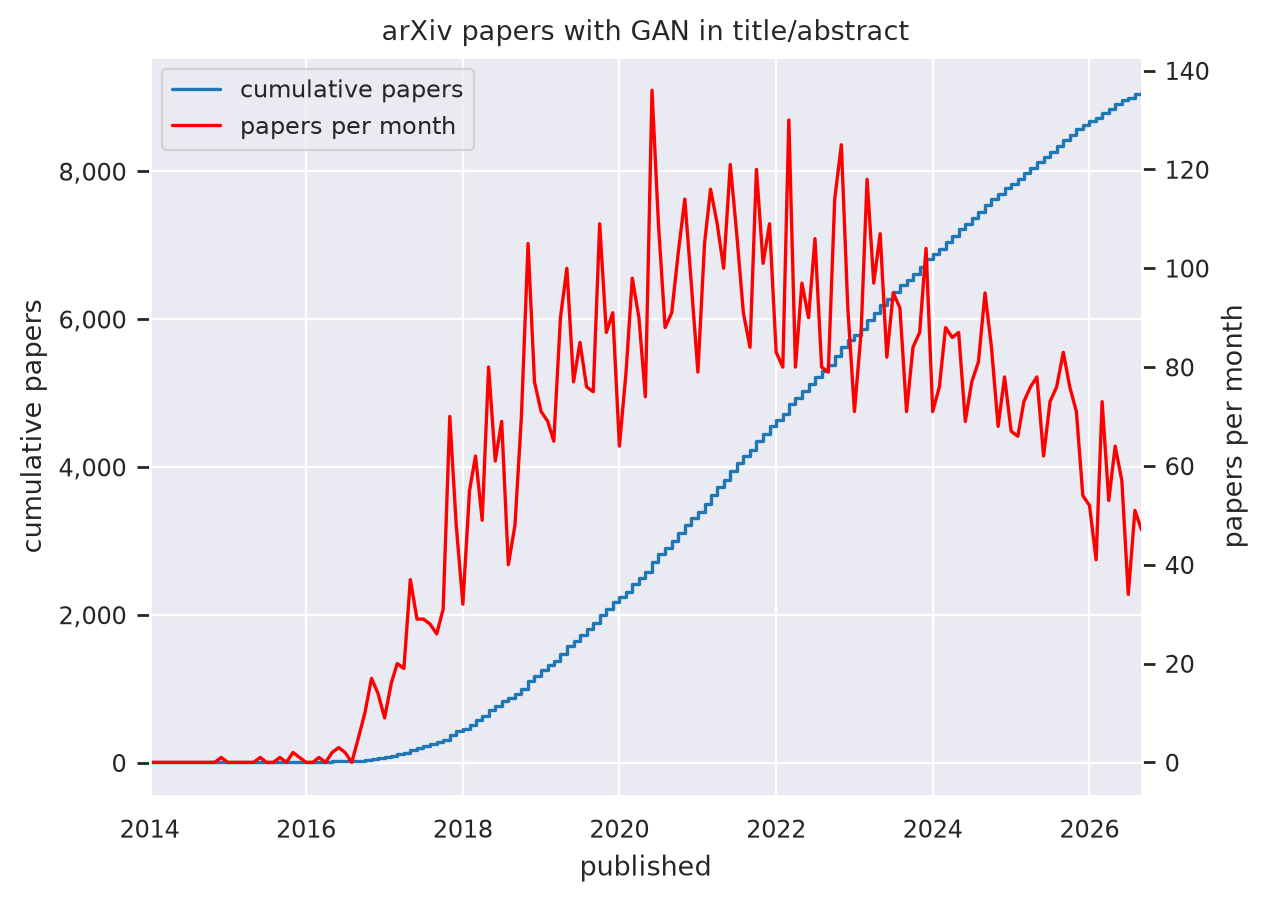

In [6]:
def plot_counts(monthly: pd.DataFrame, title: str):
    x = monthly.index.to_timestamp()
    ax = sns.lineplot(x=x, y=monthly['cumulative papers'], drawstyle='steps-post', label='cumulative papers')
    right = sns.lineplot(x=x, y=monthly['papers per month'], ax=ax.twinx(), color='red', label='papers per month')
    ax.set(xlim=(pd.Timestamp('2014-01-01'), x[-1]), xlabel='published', ylabel='cumulative papers', title=title)
    right.set(ylabel='papers per month')
    for axis in (ax, right):
        axis.yaxis.set_major_formatter('{x:,.0f}')
    right.grid(False)
    handles = ax.get_legend().legend_handles + right.get_legend().legend_handles
    right.get_legend().remove()
    ax.legend(handles, ['cumulative papers', 'papers per month'], loc='upper left')
    plt.show()


plot_counts(gan_monthly, 'arXiv papers with GAN in title/abstract')

GAN papers took off in 2017–2018 and reached about 100 per month in 2020–2022 (the most: 136 in June 2020). Since
2023 the rate has been falling, to about 50 per month in 2026: the cumulative count still grows, but more slowly.

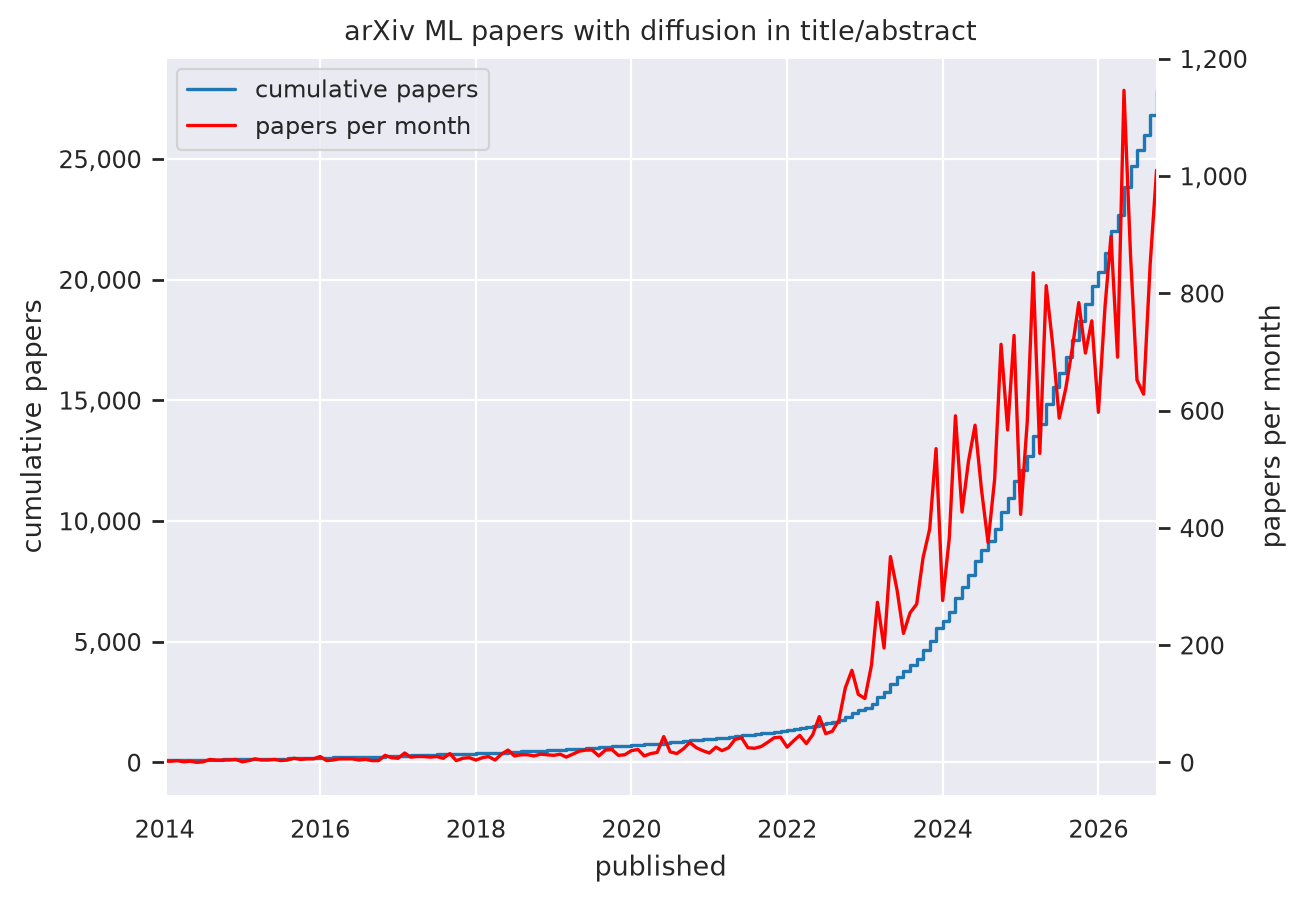

In [7]:
plot_counts(diffusion_monthly, 'arXiv ML papers with diffusion in title/abstract')

Until 2022, 10–40 papers per month — the other meanings of "diffusion" plus the first diffusion models (DDPM, June
2020; score-based models). The jump starts in the second half of 2022, the year of DALL·E 2, Imagen and the open release
of Stable Diffusion (August): more than 100 papers per month from October 2022, more than 500 from December 2023, and
about 800 per month in 2026 (the most: 1,146 in May 2026).

## GANs vs diffusion models

Both counts on the same scale, up to the last month both snapshots cover (September 2026):

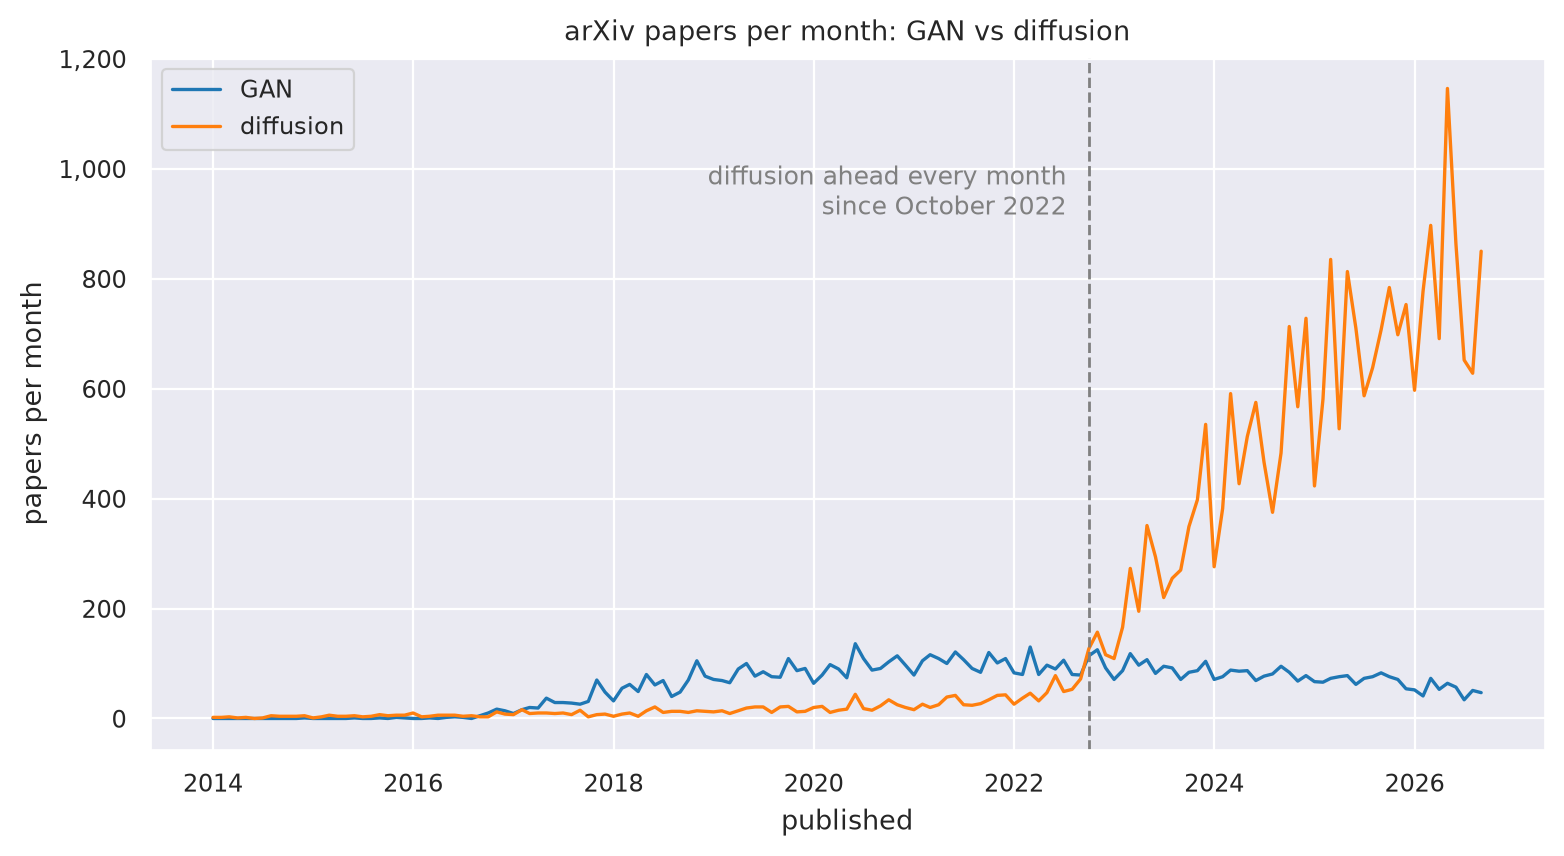

In [8]:
both = pd.DataFrame({'GAN': gan_monthly['papers per month'],
                     'diffusion': diffusion_monthly['papers per month']}).loc['2014-01':'2026-09'].fillna(0)
behind = both.index[both.diffusion <= both.GAN]
crossover = behind[-1] + 1                     # diffusion ahead in every month since

fig, ax = plt.subplots(figsize=(9, 4.5))
for column, color in [('GAN', 'C0'), ('diffusion', 'C1')]:
    ax.plot(both.index.to_timestamp(), both[column], color=color, label=column)
ax.axvline(crossover.to_timestamp(), color='gray', ls='--', lw=1)
ax.annotate(f'diffusion ahead every month\nsince {crossover:%B %Y}', (crossover.to_timestamp(), both.max().max() * 0.8),
            xytext=(-8, 0), textcoords='offset points', ha='right', fontsize=9, color='gray')
ax.set(xlabel='published', ylabel='papers per month', title='arXiv papers per month: GAN vs diffusion')
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.legend(loc='upper left')
plt.show()

In [9]:
yearly = both.groupby(both.index.year).sum().astype(int)
yearly['diffusion / GAN'] = (yearly.diffusion / yearly.GAN).round(2)
yearly.rename_axis('year').loc[2016:]  # 2026: January to September

,GAN,diffusion,diffusion / GAN
year,,,
2016,54,70,1.30
2017,362,111,0.31
2018,748,136,0.18
2019,995,189,0.19
2020,1143,264,0.23
2021,1242,363,0.29
2022,1156,840,0.73
2023,1095,3415,3.12
2024,960,6096,6.35


On the same scale, the GAN peak looks small. Diffusion has been ahead in every month since October 2022; in 2025
arXiv had 9 diffusion papers for every GAN paper, and 15 in the first nine months of 2026.

The two counts use different filters — GAN: the acronym anywhere in the entry, in all categories; diffusion: the word
in the title or abstract, in the ML categories — and the diffusion baseline before 2022 is mostly not about diffusion
models. So the ratios are approximate, but the shift of attention from GANs to diffusion models is not.